# Procedure for estimating entries of rho, the signal strength matrix. 

In [29]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
import WERM.model as model
import WERM.general_fixed_point_eqns as fp
import WERM.M_est_fixed_point_eqns as M_est
import WERM.gof
import WERM.performance_measures
import WERM.general_fixed_point_eqns as fp
import WERM.marginals
import WERM.config
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
import time
tqdm = partial(tqdm, position=0, leave=True)
import jax.random
import importlib
import WERM.estimators
importlib.reload(WERM.estimators)
importlib.reload(fp)
importlib.reload(WERM.estimators)

# Master PRNG key for reproducibility of all runs
MASTER_KEY = jax.random.PRNGKey(42)

p = 1000
L = 2 # num signals. L-1 changepoints
noise_std = 0.1

# Least Squares Loss
M = lambda u, v: jnp.power(u - v, 2)

# Huber Loss
# def M(u, v, epsilon=1.35):
#     residual = u - v
#     abs_residual = jnp.abs(residual)
#     condition = abs_residual <= epsilon
#     squared_loss = 0.5 * jnp.square(residual)
#     linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
#     return jnp.where(condition, squared_loss, linear_loss)

# Logistic loss
# M = lambda u, v: jnp.log(1 + jnp.exp(u)) - jnp.multiply(v, u)
num_trials = 1

# fractional_chgpt_locations = np.array([0.3, 0.7])
fractional_chgpt_locations = np.array([0.3])
# fractional_chgpt_locations = np.array([])
# fractional_chgpt_locations = np.array([])
# chgpt_locations = np.array([])

δ = 4.0
n = int(δ * p)
if fractional_chgpt_locations.size != 0:
    true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
    C_true = η_to_ψ(true_chgpt_locations(n), n)
else:
    true_chgpt_locations = lambda n: np.array([])
    C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

# --- Preliminaries ---
# --- Compute weights as marginals of prior --- #
Δ = lambda n: 1
Delta_n = int(Δ(n))
L_is_upper_bound = False
if Delta_n ==1 : # No separation between change points, so use analytical binomial approximation. 
    if L_is_upper_bound:
        pi_i_l = lambda L, l, i : 1/(L - l + 1) * np.sum([scipy.special.comb(k - 1, l- 1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(k-l) for k in range(l, L+1)])
    else: 
        pi_i_l = lambda L,l , i: scipy.special.comb(L-1, l-1, exact=False) * (i/n)**(l-1) * (1 - i/n)**(L-l)
    # Populate the pi L times n matrix
    pi = np.zeros((L, n))
    for l in range(L):
        for i in range(n):
            pi[l, i] = pi_i_l(L, l + 1, i + 1)
else: 
    n_small = 100
    Delta_n_small = int(Delta_n * n_small/n)
    if L_is_upper_bound: 
        p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
        Lmin = 1
        Lmax = L
    else:
        p_l = None
        Lmin = L
        Lmax = L
    pi = WERM.config.extrapolated_marginals(Lmin, Lmax, Delta_n_small, n_small = n_small, n_large = n, p_l = p_l, verbose = False)
π = pi
if L == 1: 
    π = np.ones((1, n))
print("Sum of row weights: ", π.sum(axis=1))
# Normalize rows to sum to 1
# row_sums = π.sum(axis=1, keepdims=True)
# π = π / row_sums
# # Plot pi
# plt.plot(π.T)
# plt.title("Marginal weights π")
# plt.xlabel("Sample index i")
# plt.ylabel("Weight π(l,i)")
# plt.show()

# Gaussian Signal Prior
κ = 1.0
B̃_cov = κ**2 * δ * np.eye(L) # keeps the signal power fixed
B̃_cov[0, 1] = -0.4
B̃_cov[1, 0] = -0.4  # Introduce some correlation between the signals
# B̃_cov = κ**2 * δ * np.array([[1.0, 0.0], [0.0, 1.0]]) # keeps the signal power fixed
signal_prior = GaussianSignal(B̃_cov)

B̃ = signal_prior.sample(p)
ρ = 1/δ * 1/p * B̃.T @ B̃
key = jax.random.PRNGKey(0)


ε = np.random.randn(n) * noise_std

# load the fixed point solutions from a file if they exist
# import pickle
# try:
#     with open('results/all_fp_solns.pkl', 'rb') as f:
#         all_fp_solns = pickle.load(f)
# except FileNotFoundError:
#     all_fp_solns = fp.compute_all_fixed_points(n, L, Δ(n), M, ρ, δ, π, None, n, model.q_linear_model, MASTER_KEY, coarse_grain_factor=4)
#     with open('results/all_fp_solns.pkl', 'wb') as f:
#         pickle.dump(all_fp_solns, f)

# all_fp_solns = fp.compute_all_fixed_points(n, L, Δ(n), M, ρ, δ, π, ε, n, model.q_linear_model, MASTER_KEY, coarse_grain_factor=4)

for trial_num in tqdm(range(num_trials)):
    # Generate the observation vector Y
    X = np.random.normal(0, np.sqrt(1/n), (n, p))

    # ε = jax.random.t(key, 5, shape=(n, ))
    # ε = np.random.standard_t(5, size=(n, ))
    # ε = np.random.uniform(0, 1, size=(n, ))

    Θ = X @ B̃
    # y = lin_reg(Θ, C_true, noise_std).astype(np.float64).flatten()
    y_fn = jax.vmap(model.q_linear_model, in_axes=(0, 0, 0), out_axes=0)
    y = y_fn(Θ, C_true, ε)
    # y = jax.vmap(model.q_logistic_model, in_axes = (0, 0, 0))(Θ, C_true, ε)

    cp, gof, B̂ = WERM.estimators.weighted_erm(X, y, M, L, Δ(n), 0.0, L_is_upper_bound=L_is_upper_bound, brute_force=False, 
                                               return_gof=True, return_B_hat=True)
    
    
# Save all_fp_solns to a file
# import pickle
# with open('results/all_fp_solns.pkl', 'wb') as f:
#     pickle.dump(all_fp_solns, f)


Sum of row weights:  [1999.5 2000.5]


  0%|          | 0/1 [00:00<?, ?it/s]

  Tested 3999 valid positions
  Best 5 improvements: [(1200, Array(1156.06493453, dtype=float64), Array(494.0376634, dtype=float64)), (1199, Array(1155.59038564, dtype=float64), Array(494.51221228, dtype=float64)), (1201, Array(1155.36391465, dtype=float64), Array(494.73868327, dtype=float64)), (1202, Array(1155.2108309, dtype=float64), Array(494.89176702, dtype=float64)), (1203, Array(1155.20139875, dtype=float64), Array(494.90119917, dtype=float64))]

Applying local refinement...


100%|██████████| 1/1 [00:04<00:00,  4.30s/it]


In [2]:
nu_arr = np.array([lis[2] for lis in all_fp_solns]).reshape((-1, L, L))
# Print how many nu in nu_arr are invertible
print("Number of invertible nu matrices:", np.sum([np.linalg.matrix_rank(nu) == L for nu in nu_arr]))
print("Shape of nu_arr:", nu_arr.shape)
# Print the determinant of the nu matrices
det_nu = np.array([np.linalg.det(nu) for nu in nu_arr])
print("Determinant of nu matrices:", det_nu)
# Plot the histogram of the determinant of the nu matrices
plt.hist(det_nu, bins=50)
plt.xlabel('Determinant of nu matrices')
plt.ylabel('Frequency')
plt.title('Histogram of Determinant of nu matrices')
plt.show()

# Print how many nu are positive definite
print("Number of positive definite nu matrices:", np.sum([np.all(np.linalg.eigvals(nu) > 0) for nu in nu_arr]))
# Print how many nu are negative definite
print("Number of negative definite nu matrices:", np.sum([np.all(np.linalg.eigvals(nu) < 0) for nu in nu_arr]))
# Print how many nu are indefinite
print("Number of indefinite nu matrices:", np.sum([np.any(np.linalg.eigvals(nu) < 0) and np.any(np.linalg.eigvals(nu) > 0) for nu in nu_arr]))

# Print the indefinite nu matrices
indefinite_nu = [nu for nu in nu_arr if np.any(np.linalg.eigvals(nu) < 0) and np.any(np.linalg.eigvals(nu) > 0)]
print("Indefinite nu matrices:")
for nu in indefinite_nu:
    print(nu)
    print("Eigenvalues:", np.linalg.eigvals(nu))
    print("Determinant:", np.linalg.det(nu))
    print("Rank:", np.linalg.matrix_rank(nu))
    print("Positive definite:", np.all(np.linalg.eigvals(nu) > 0))
    print("Negative definite:", np.all(np.linalg.eigvals(nu) < 0))
    print("Indefinite:", np.any(np.linalg.eigvals(nu) < 0) and np.any(np.linalg.eigvals(nu) > 0))
    print()

# Print number of symmetric nu matrices
print("Number of symmetric nu matrices:", np.sum([np.allclose(nu, nu.T) for nu in nu_arr]))
# Print number of non-symmetric nu matrices
print("Number of non-symmetric nu matrices:", np.sum([not np.allclose(nu, nu.T) for nu in nu_arr]))

NameError: name 'all_fp_solns' is not defined

In [4]:
import importlib
import WERM.posterior
importlib.reload(WERM.posterior)

print("L:  ", L)
# Estimate ρ
b, nu, kappa, rho_hat = WERM.posterior.estimate_rho(X, y, M, π, δ, Δ(n), ε, model.q_linear_model, L_is_upper_bound=L_is_upper_bound, brute_force=False, true_chgpt_locations=fractional_chgpt_locations, rho_0 = 0.5*np.eye(L), rho_est_weight=1.0)
print("True ρ:", ρ)
# rho_hat = WERM.posterior.estimate_rho_iterative(X, y, M, π, L, δ, Δ(n), ε, model.q_linear_model, num_iters = 5, rho_0 = 0.1*np.eye(L), L_is_upper_bound=L_is_upper_bound, true_chgpt_locations=fractional_chgpt_locations)
print("Estimated ρ:", rho_hat)
print("fractional error in rho: ", np.linalg.norm(rho_hat - ρ) / np.linalg.norm(ρ))
# rhs = nu.T @ rho_hat @ nu + kappa
# print("Right-hand side for estimating ρ:", rhs)

# Print final differences between rho_hat and ρ
print("Final difference between rho_hat and ρ:", (rho_hat - ρ))


Theta_hat = X @ B̂
Theta_deb = WERM.posterior.compute_debiased_theta(Theta_hat, y, M, π, δ)

cp_arr = np.array([lis[0] for lis in all_fp_solns])
nu_arr = np.array([lis[2] for lis in all_fp_solns]).reshape((-1, L, L))
kappa_arr = np.array([lis[3] for lis in all_fp_solns]).reshape((-1, L, L))
print(cp_arr.shape)
p_η_arr = np.ones((len(cp_arr),)) / len(cp_arr)  # Uniform prior over changepoint

σ = noise_std
posterior = WERM.posterior.exact_posterior_gaussian(cp_arr, p_η_arr, Theta_deb, y, ρ, σ, nu_arr, kappa_arr)

L:   2
Estimating change point locations using weighted ERM...
  Tested 3999 valid positions
  Best 5 improvements: [(1199, Array(1261.68136439, dtype=float64), Array(548.110911, dtype=float64)), (1200, Array(1261.60720729, dtype=float64), Array(548.1850681, dtype=float64)), (1201, Array(1261.20225866, dtype=float64), Array(548.59001673, dtype=float64)), (1202, Array(1261.03264613, dtype=float64), Array(548.75962926, dtype=float64)), (1203, Array(1260.90430863, dtype=float64), Array(548.88796676, dtype=float64))]

Applying local refinement...
Change point locations estimated: [1199]
Computing debiased Theta estimate...
Debiased Theta estimate computed.
Left-hand side for estimating ρ: [[0.72952889 0.57519454]
 [0.57519454 0.83901499]]
Optimization Results: all =       message: The maximum number of function evaluations is exceeded.
     success: False
      status: 0
         fun: [-2.420e-03  8.930e-04 -2.598e-04  4.612e-04  1.155e-04
                5.675e-05  5.675e-05 -2.077e-04 -1

NameError: name 'all_fp_solns' is not defined

### Estimate rho diagonals

In [5]:
import importlib
import WERM.posterior
importlib.reload(WERM.posterior)
# Estimate the rho diagonals iteratively:
chgpt_est = cp
print("Estimated changepoints:", chgpt_est)
print("True rho: ", ρ)

# # Split the data (X, y) into segments according to the estimated changepoints
# if chgpt_est.size > 0:
#     X_segments = np.split(X, chgpt_est)
#     y_segments = np.split(y, chgpt_est)
#     ε_segments = np.split(ε, chgpt_est)
# else:
#     X_segments = [X]
#     y_segments = [y]
#     ε_segments = [ε]

# L_eff = 1
# rho_hat_diag = np.eye(L)
# for (l, data_seg) in enumerate(zip(X_segments, y_segments, ε_segments)):
#     X_seg, y_seg, ε_seg = data_seg
#     print("Segment", l, "size:", X_seg.shape, y_seg.shape, ε_seg.shape)
#     n_eff = X_seg.shape[0]  # Effective n for the segment
#     δ_eff = (n_eff/p)  # Effective δ for the segment
#     print("Effective n:", n_eff, "Effective δ:", δ_eff)
#     pi_eff = np.ones((1, n_eff)) / n_eff  # Uniform prior for the segment
#     rho_hat_l = WERM.posterior.estimate_rho_iterative(X_seg, y_seg, M, pi_eff, L_eff, δ_eff, 1, ε_seg, model.q_linear_model, num_iters = 5, 
#                                                     rho_0 = 0.1*np.eye(L_eff), L_is_upper_bound=L_is_upper_bound, true_chgpt_locations=np.array([]),
#                                                     brute_force=False)
#     rho_hat_diag[l, l] = rho_hat_l[0]

rho_hat_diag = WERM.posterior.estimate_rho_diagonals(X, y, M, L, Δ(n), ε, model.q_linear_model, 
                                                     L_is_upper_bound=L_is_upper_bound, true_chgpt_locations=true_chgpt_locations(n), brute_force=False)

print("rho hat diagonal:", rho_hat_diag)
print("True rho: ", ρ)

Estimated changepoints: [1199]
True rho:  [[ 1.02474848 -0.10325878]
 [-0.10325878  1.02564566]]
Estimating change point locations using weighted ERM...
Change point locations estimated: []
Computing debiased Theta estimate...
Debiased Theta estimate computed.
Left-hand side for estimating ρ: [[1.09024728]]


  0%|          | 0/5 [00:00<?, ?it/s]

Current estimate of ρ: [[0.1]]
Optimization Results: all =       message: `gtol` termination condition is satisfied.
     success: True
      status: 1
         fun: [-6.733e-13  7.191e-10 -2.325e-12]
           x: [ 3.000e+03  1.000e+00  2.209e-01]
        cost: 2.585634611328092e-19
         jac: [[ 4.630e-05  0.000e+00  0.000e+00]
               [-1.092e-08 -8.275e-02 -1.142e-03]
               [-5.421e-06 -3.931e-04  7.304e-02]]
        grad: [-2.642e-17 -5.950e-11 -9.911e-13]
  optimality: 5.950417532096619e-11
 active_mask: [0 0 0]
        nfev: 16
        njev: 16 success =  True , message =  `gtol` termination condition is satisfied.
b - b_hat: [68.18270749]
b: [2999.99999999]
b_hat: [2931.8172925]
nu:  [[1.00031587]]
Rank of nu: 1
Eigenvalues of nu: [1.00031587]
kappa:  [[0.04879125]]
Rank of kappa: 1
Eigenvalues of kappa: [0.04879125]
Optimization converged: True
Number of function evaluations: 7
Final objective norm: 1.4011014570769476e-13
Minimum eigenvalue: 1.0407984102829

  0%|          | 0/5 [00:00<?, ?it/s]

Current estimate of ρ: [[0.1]]
Optimization Results: all =       message: `gtol` termination condition is satisfied.
     success: True
      status: 1
         fun: [-1.351e-06  1.821e-07 -6.638e-08]
           x: [ 7.778e+02  1.000e+00  7.438e-02]
        cost: 9.317125976400636e-13
         jac: [[ 2.952e-04  0.000e+00  0.000e+00]
               [-1.571e-08 -3.585e-02 -2.788e-04]
               [-9.146e-06 -3.802e-05  9.567e-02]]
        grad: [-3.983e-10 -6.525e-09 -6.401e-09]
  optimality: 6.5247056483582195e-09
 active_mask: [0 0 0]
        nfev: 12
        njev: 12 success =  True , message =  `gtol` termination condition is satisfied.
b - b_hat: [777.67269021]
b: [777.77320024]
b_hat: [0.10051003]
nu:  [[0.99999527]]
Rank of nu: 1
Eigenvalues of nu: [0.99999527]
kappa:  [[0.00553253]]
Rank of kappa: 1
Eigenvalues of kappa: [0.00553253]
Optimization converged: True
Number of function evaluations: 7
Final objective norm: 6.483702463810914e-14
Minimum eigenvalue: 1.01511297352856


In [35]:
np.diag(rho_hat_diag)

array([[0.9997172 , 0.        ],
       [0.        , 1.07959121]])

### Estimate rho off-diagonals -> Works for the full ρ now. 

In [28]:
import importlib
import WERM.posterior
importlib.reload(WERM.posterior)
importlib.reload(fp)
print("True chgpt locations:", true_chgpt_locations(n))
print("Estimated changepoints:", cp)
print("True rho: ", ρ)
exact_rho_diag = np.diag(ρ)
full_rho_est_list = WERM.posterior.estimate_rho_iterative(X, y, M, π, L, δ, Δ(n), ε, model.q_linear_model, 
                                                     num_iters = 6, rho_0 = 0.5*jnp.eye(L),
                                                     L_is_upper_bound=L_is_upper_bound, true_chgpt_locations=true_chgpt_locations(n), brute_force=False,
                                                     rho_list_output=True
                                                     )
print("True rho: ", ρ) 
print("Final Estimated rho: ", full_rho_est_list[-1])

True chgpt locations: [1200]
Estimated changepoints: [1201]
True rho:  [[ 1.01897097 -0.07039272]
 [-0.07039272  0.99084714]]
Estimating change point locations using weighted ERM...
  Tested 3999 valid positions
  Best 5 improvements: [(1201, Array(1132.10409999, dtype=float64), Array(498.39758129, dtype=float64)), (1200, Array(1132.03977862, dtype=float64), Array(498.46190266, dtype=float64)), (1206, Array(1131.61840704, dtype=float64), Array(498.88327425, dtype=float64)), (1205, Array(1131.59219377, dtype=float64), Array(498.90948751, dtype=float64)), (1204, Array(1131.55720814, dtype=float64), Array(498.94447314, dtype=float64))]

Applying local refinement...
Change point locations estimated: [1201]
Computing debiased Theta estimate...
Debiased Theta estimate computed.
Left-hand side for estimating ρ: [[0.71626533 0.59090858]
 [0.59090858 0.84691869]]


  0%|          | 0/6 [00:00<?, ?it/s]

Current estimate of ρ: [[0.5 0. ]
 [0.  0.5]]
  Tested 3999 valid positions
  Best 5 improvements: [(1201, Array(1132.10409999, dtype=float64), Array(498.39758129, dtype=float64)), (1200, Array(1132.03977862, dtype=float64), Array(498.46190266, dtype=float64)), (1206, Array(1131.61840704, dtype=float64), Array(498.88327425, dtype=float64)), (1205, Array(1131.59219377, dtype=float64), Array(498.90948751, dtype=float64)), (1204, Array(1131.55720814, dtype=float64), Array(498.94447314, dtype=float64))]

Applying local refinement...
Using estimated b_hat = [0.36690827 0.36668443] to constrain b in [[0.33021744 0.33001598], [0.4035991  0.40335287]]
Optimization Results: all =       message: `gtol` termination condition is satisfied.
     success: True
      status: 1
         fun: [ 1.701e-13  2.785e-12 -3.143e-13 -1.336e-12  3.087e-13
                1.322e-12  2.023e-12 -5.464e-12 -5.464e-12  3.091e-11]
           x: [ 3.669e-01  3.667e-01  4.600e-01  1.158e-01  5.382e-01
                

Full rho estimate with off-diagonal elements: [[ 1.05052075 -0.10640321]
 [-0.10640321  1.01049447]]
Fractional error in full rho estimate: 0.020741992051390046
True rho: [[ 1.02474848 -0.10325878]
 [-0.10325878  1.02564566]]
Rho estimate 0:
 [[ 1.72941019 -0.11210639]
 [-0.11210639  1.03541786]]
Fractional error in rho estimate: 0.48370066720465715


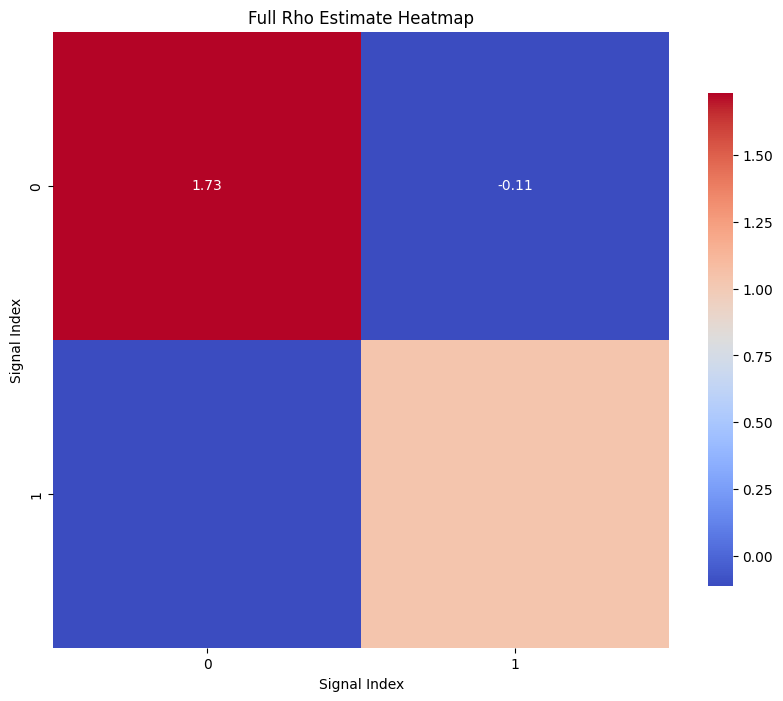

Rho estimate 1:
 [[ 0.67790319 -0.10427867]
 [-0.10427867  0.99669561]]
Fractional error in rho estimate: 0.2388542069512414


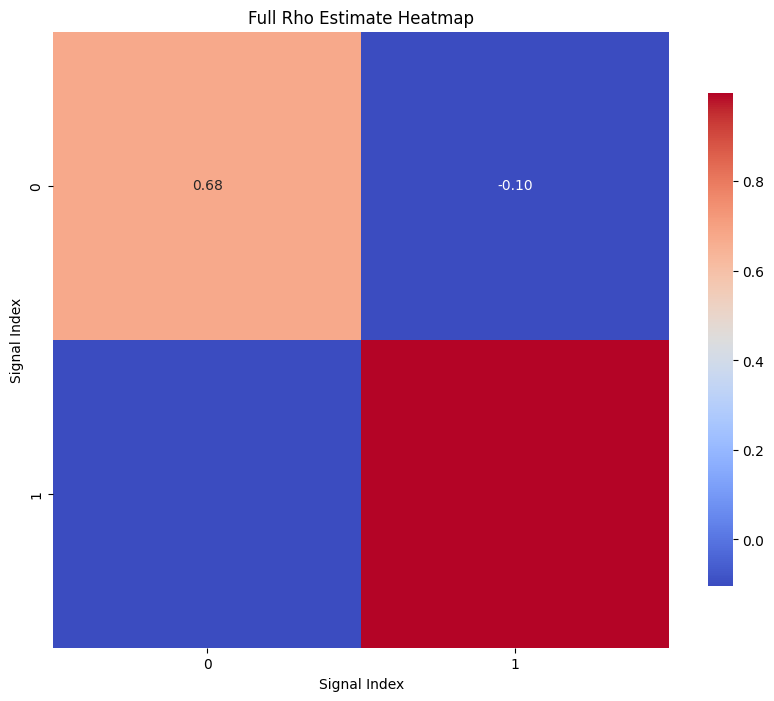

Rho estimate 2:
 [[ 1.26354683 -0.10759656]
 [-0.10759656  1.01833637]]
Fractional error in rho estimate: 0.16400746579045902


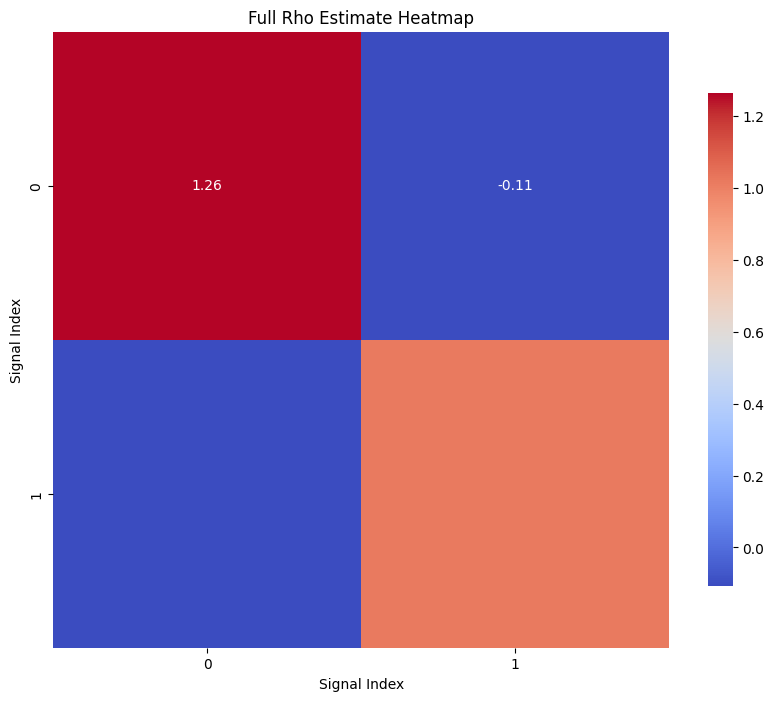

Rho estimate 3:
 [[ 0.93766324 -0.10577214]
 [-0.10577214  1.00632279]]
Fractional error in rho estimate: 0.061264767246619556


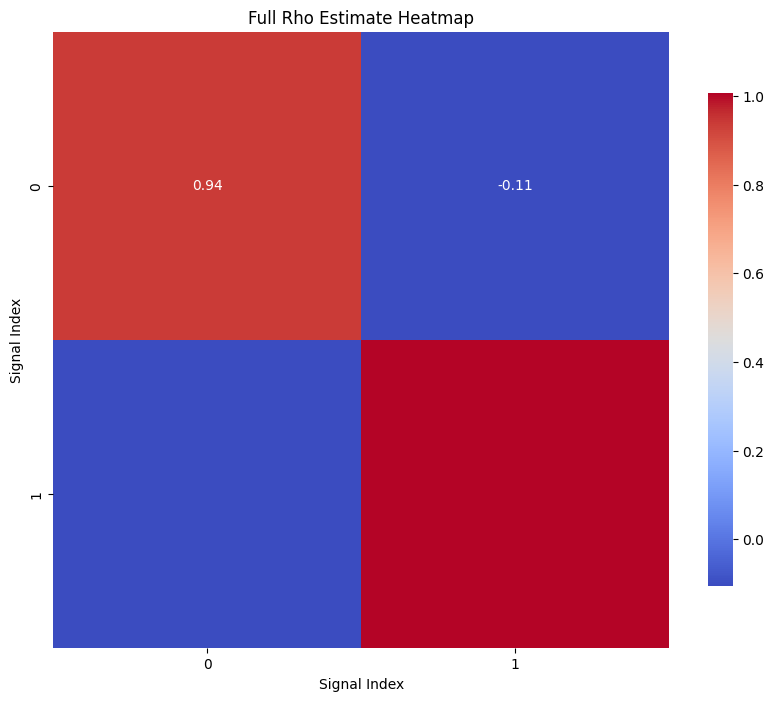

Rho estimate 4:
 [[ 1.11856176 -0.10678084]
 [-0.10678084  1.01300462]]
Fractional error in rho estimate: 0.06505157969024476


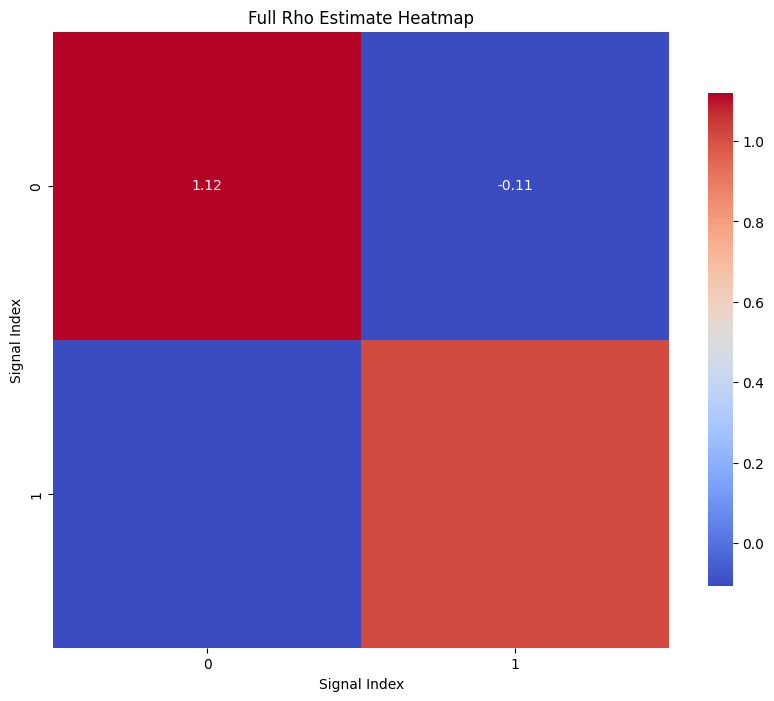

Rho estimate 5:
 [[ 1.01805821 -0.10622211]
 [-0.10622211  1.00929519]]
Fractional error in rho estimate: 0.012460030294037163


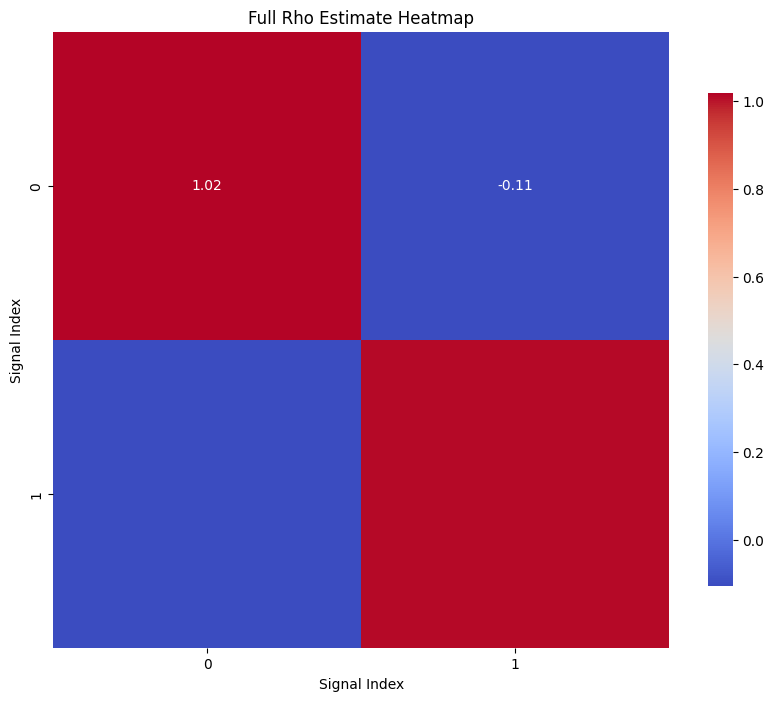

Rho estimate 6:
 [[ 1.07386231 -0.10653292]
 [-0.10653292  1.01135611]]
Fractional error in rho estimate: 0.035245748723592256


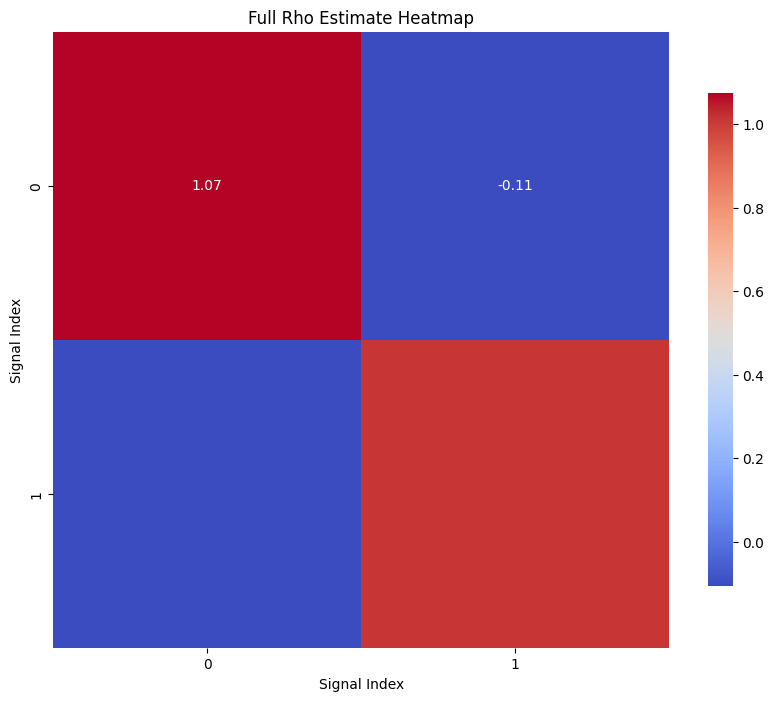

Rho estimate 7:
 [[ 1.04286787 -0.10636065]
 [-0.10636065  1.01021188]]
Fractional error in rho estimate: 0.016609042787527485


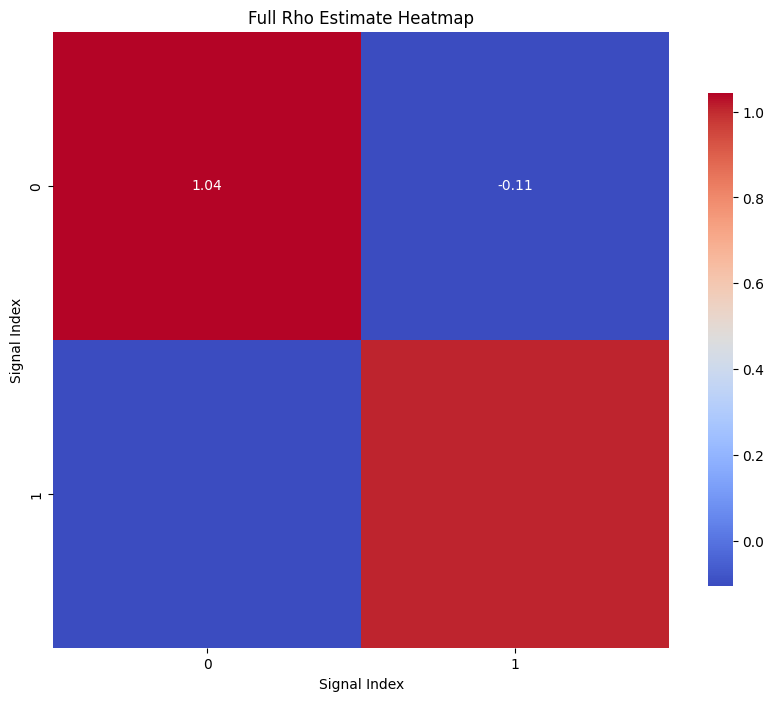

Rho estimate 8:
 [[ 1.06007926 -0.10645635]
 [-0.10645635  1.01084737]]
Fractional error in rho estimate: 0.026469387618856116


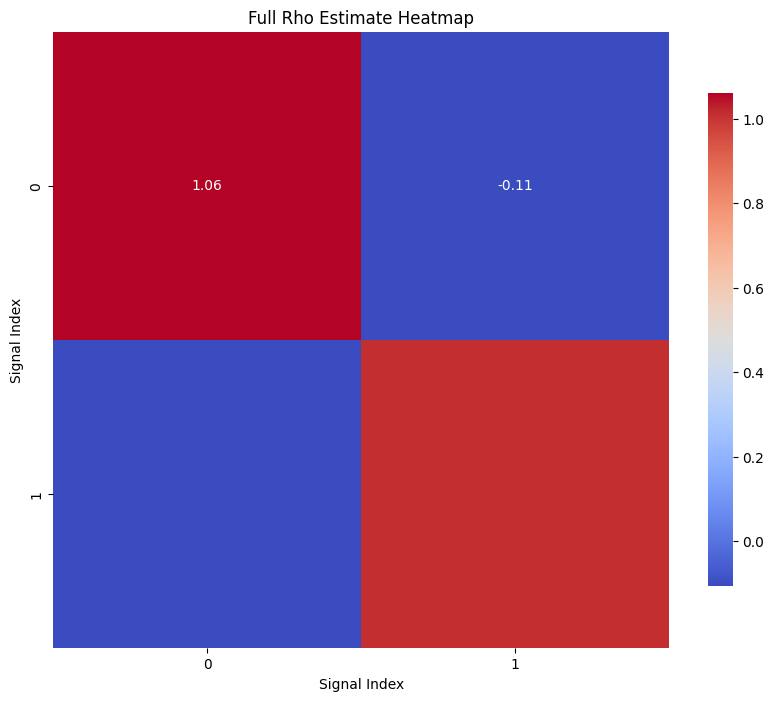

Rho estimate 9:
 [[ 1.05052075 -0.10640321]
 [-0.10640321  1.01049447]]
Fractional error in rho estimate: 0.020741992051390046


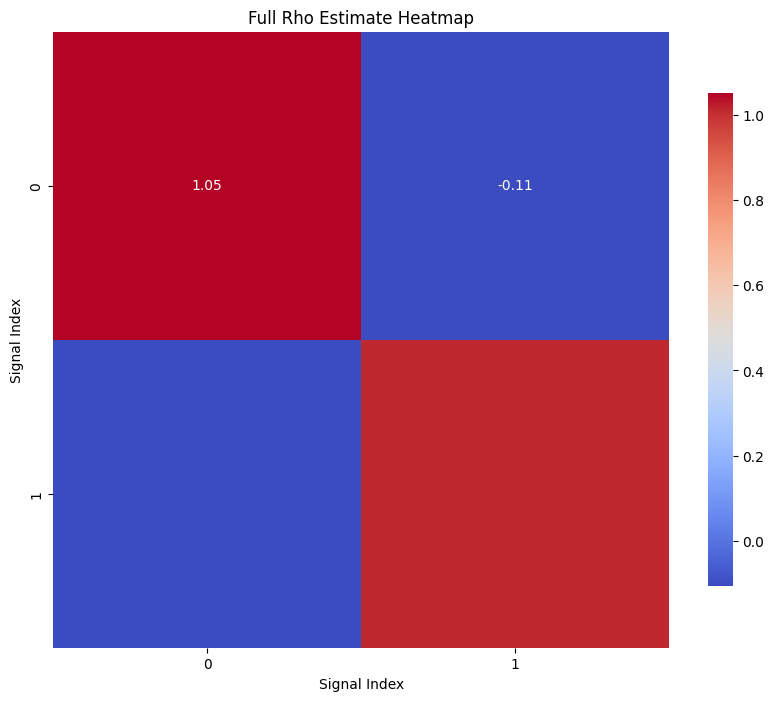

In [14]:
# Visualize the list of rho estimates, plot a heatmap of all estimates
full_rho_est = full_rho_est_list[-1]
print("Full rho estimate with off-diagonal elements:", full_rho_est)
print("Fractional error in full rho estimate:", np.linalg.norm(full_rho_est - ρ) / np.linalg.norm(ρ))
print("True rho:", ρ)

import seaborn as sns
for i, rho_est in enumerate(full_rho_est_list):
    print(f"Rho estimate {i}:\n", rho_est)
    print("Fractional error in rho estimate:", np.linalg.norm(rho_est - ρ) / np.linalg.norm(ρ))
    plt.figure(figsize=(10, 8))
    sns.heatmap(rho_est, annot=True, fmt=".2f", cmap="coolwarm", square=True, cbar_kws={"shrink": .8})
    plt.title("Full Rho Estimate Heatmap")
    plt.xlabel("Signal Index")
    plt.ylabel("Signal Index")
    plt.show()

In [29]:
print("True rho: ", ρ)
print("Full rho estimate with off-diagonal elements:", full_rho_est)
print("Fractional error in full rho estimate:", np.linalg.norm(full_rho_est - ρ) / np.linalg.norm(ρ))

True rho:  [[ 1.02756195 -0.05840214]
 [-0.05840214  0.90658208]]
Full rho estimate with off-diagonal elements: [[1.00069871 0.94452983]
 [0.94452983 0.89157325]]
Fractional error in full rho estimate: 1.0334262707531001


In [16]:
# Naive estimate of rho: 
rho_naive = 1/δ * 1/p * B̂.T @ B̂
print("Naive rho estimate:", rho_naive)


Naive rho estimate: [[0.68432417 0.5097612 ]
 [0.5097612  0.73703837]]


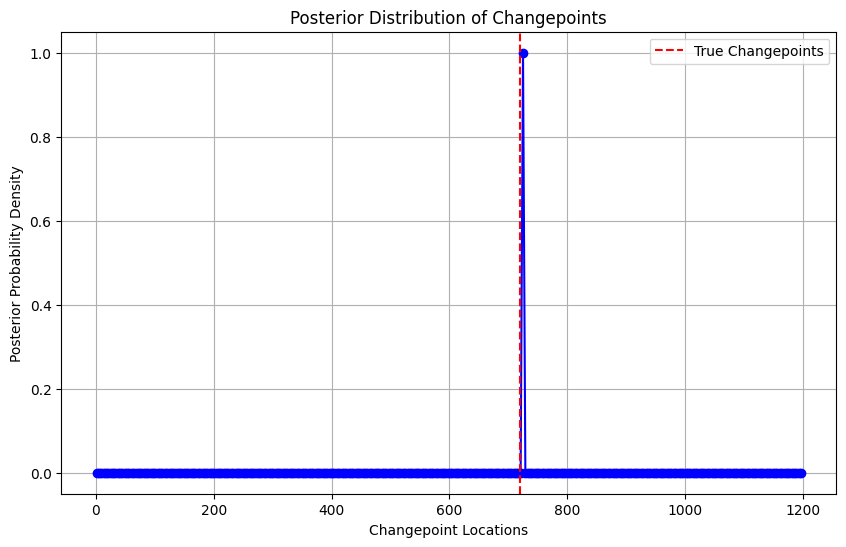

In [ ]:
# Plot the posterior

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.plot(cp_arr, posterior, marker='o', linestyle='-', color='b')
# Plot a dashed vertical line at fractional changepoint locations * n
plt.axvline(x=true_chgpt_locations(n), color='r', linestyle='--', label='True Changepoints')
plt.legend()
plt.title('Posterior Distribution of Changepoints')
plt.xlabel('Changepoint Locations')
plt.ylabel('Posterior Probability Density')
plt.grid()
plt.show()